In [ ]:
Module 6 - Forecasting Public Transportation Demand - Samuel Scott

## Part 1: Business Situation
### The Setting
Forecasting transportation demand matters for staffing, planning, and inventory control. The public
transportation system in Santiago de Chile went through a major effort of reconstruction, and in that
context a business intelligence competition was held in October 2006 focused on forecasting demand for
public transportation. This case is based on that competition, with some modifications.
A public transportation company is expecting an increase in demand for its services and is planning to
acquire new buses and extend its terminals. These investments require a reliable forecast of future
demand. The company's data warehouse holds, for each 15-minute interval between 6:30 and 22:00, the
number of passengers arriving at the terminal. As a forecasting consultant, you have been asked to
create a method that generates forecasts of the number of passengers arriving at the terminal

### The Data
Part of the historic information is available in Bicup2006.csv. The dataset holds known demand for a
three-week period (March 1 to March 21, 2005), separated into 15-minute intervals from 6:30 to 22:00 (63
intervals per day). It also contains the dates and times for a future three-day period with DEMAND left
blank (NaN), for which forecasts must be generated. Each row is one 15-minute interval and holds three
fields.

In [1]:
from datetime import date
import matplotlib.pyplot as plt
import mlba
import pandas as pd
from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.trend import PolynomialTrendForecaster
from sktime.split import temporal_train_test_split
from sktime.utils.plotting import plot_series
from sktime.forecasting.ardl import ARDL
from sktime.forecasting.arima import ARIMA
from sktime.forecasting.base import ForecastingHorizon
from sktime.forecasting.trend import PolynomialTrendForecaster, TrendForecaster
from sktime.pipeline import make_pipeline
from sktime.transformations.series.boxcox import LogTransformer
from sktime.utils.plotting import plot_series
from statsmodels.graphics.tsaplots import plot_acf

### Question 1 - Exploratory Analysis

Use exploratory analysis to understand the series before you model it. Work through the following,
showing the plots and summaries that support each conclusion.

In [2]:
df = pd.read_csv('C:/Users/samsc/Desktop/ADS-505/bicup2006.csv')
df.head()

,DATE,TIME,DEMAND
0,1-Mar-05,6:30,1.0
1,1-Mar-05,6:45,2.0
2,1-Mar-05,7:00,4.0
3,1-Mar-05,7:15,0.0
4,1-Mar-05,7:30,10.0


In [3]:
df.shape

(1512, 3)

In [60]:
df.isna().sum()

DATE             0
TIME             0
DEMAND         189
DATETIME         0
HOUR             0
DAY_OF_WEEK      0
dtype: int64

In [ ]:
df.duplicated().sum() #no duplicates

In [10]:
#Checks for when passengers arrival 
df['DEMAND'].describe()

count    1323.000000
mean       25.872260
std        23.522793
min         0.000000
25%         4.000000
50%        23.000000
75%        40.000000
max       136.000000
Name: DEMAND, dtype: float64

### Approach to dealing with missing data:

### How many passengers on average throughout the day take the public transportation?

HOUR
6      1
7      6
8     11
9     14
10    18
11    23
12    30
13    37
14    31
15    24
16    24
17    32
18    54
19    50
20    31
21    14
22     4
Name: DEMAND, dtype: int64


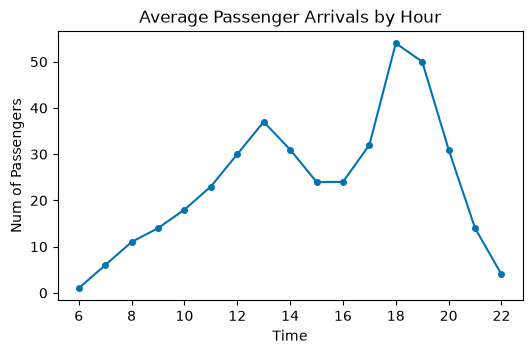

In [41]:
df['DATETIME'] = pd.to_datetime(df['DATE'] + ' ' + df['TIME'], format='%d-%b-%y %H:%M') 
public_trans_ts = pd.Series(df.DEMAND.values, index=df.DATETIME, name='Passengers')

#be able to graph the hours of the day
df['HOUR'] = df['DATETIME'].dt.hour
hourly_demand = df.groupby('HOUR')['DEMAND'].mean().astype('int') #make hourly_demand integer because demand is 
#number of people, which are not decimal values
#print(hourly_demand)

public_trans_ts = pd.Series(hourly_demand.values, index=hourly_demand.index, name='Passenger_Hours')

fig, ax = plt.subplots(figsize=[6, 3.5])
plot_series(public_trans_ts, ax=ax,
            x_label='Time', y_label='Num of Passengers')
plt.title("Average Passenger Arrivals by Hour")
plt.show()

### What days do passengers get on the public transportation (PT) the most? The least? 

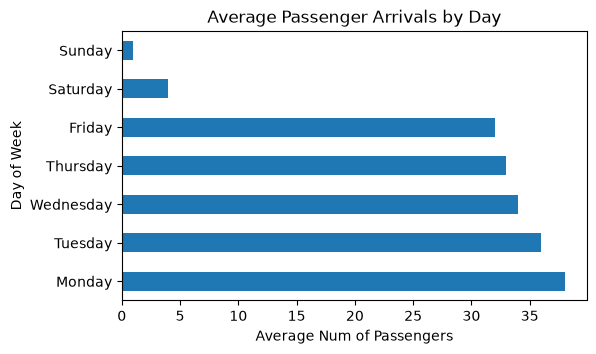

In [51]:
df['DAY_OF_WEEK'] = df['DATETIME'].dt.day_name()

daily_demand = df.groupby('DAY_OF_WEEK')['DEMAND'].mean().astype('int')
#print(daily_demand)

#reorder days of week since they are sorted by lexiographically order of day name
#used AI to help me sort the days in order
day_sort = ['Monday', 'Tuesday', 'Wednesday',
            'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_demand = daily_demand.reindex(day_sort)

fig, ax = plt.subplots(figsize=[6, 3.5])
daily_demand.plot(kind='barh', ax=ax)
plt.title("Average Passenger Arrivals by Day")
plt.ylabel('Day of Week')
plt.xlabel('Average Num of Passengers')
plt.show()

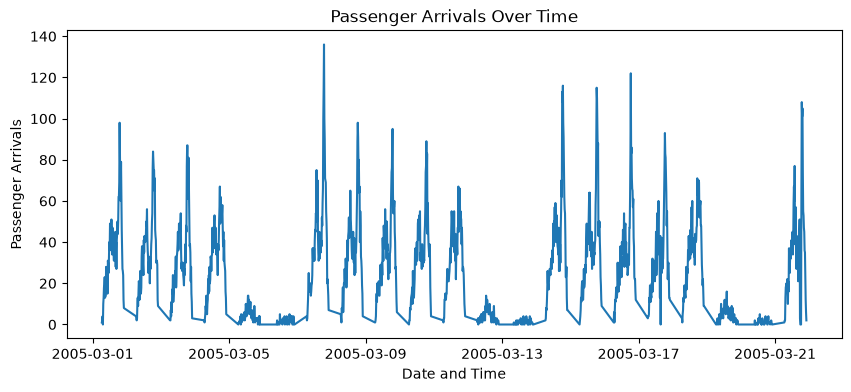

In [63]:
#Overall time series
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(df['DATETIME'], df['DEMAND'])

ax.set_xlabel('Date and Time')
ax.set_ylabel('Passenger Arrivals')
ax.set_title('Passenger Arrivals Over Time')
plt.show()

#### 1.1 Identify the Time-Series Components
Is there a trend? Is there seasonality, and if so, how many seasonal cycles are present? Are there other
visible patterns? Are the patterns global (stable across the whole series) or local (changing over time)?

There are some trends that have been identified. First, the two visuals show that passengers travel or use PT for commuting to work mainly. This conclusion can be determined because the average daily passengers significantly decrease during the weekend days, and for the hours's time series passengers averages are highest between the hours of 10am-8pm. There are ever present season cycles but the peak in passenger values vary mainly on what day and especially what time of day it is. Due to that there are season, on the time series it is clear when there are two smaller amplitudes those represent Saturday and Sunday. These patterns I would say are global as I would imagine the time series throughout the whole year would look somewhat similar as these days are in the month of March, with the exception of the holiday season (Late November-Early January).

#### 1.2 Consider the Data Frequency
Consider the frequency of the data from both a practical and a technical point of view. What are some
options for how the frequency could be treated, and what are the trade-offs?

Frequency can be determined by what measurement you use for the time series as there are several approaches. The first approach is to not change the time-frequency and leave it up to 15 minute intervals. This would get the most accurate representation of your data but since they are so many data points it would be difficult to visual represent it and it would be the most computationally expensive data to build a model on, given you would use the same model for each approach. The second approach is to use hourly intervals and aggregate passenger amounts based on how many passengers on average are tracked. This would give us a better understanding of trends (like that it tracks people commuting on a work day vs it is late at night people are asleep). This would be easier to graph but not by much, since there would still be many intervals to track. Another approach is to use days as your unit of measure for the time series. I believe this approach would be best because it would be easiest to see trends and it would still retain most of the information the time series would need to estimate future predictive values. 

#### 1.3 Compare Weekdays and Weekends
Compare weekdays and weekends. How does the demand pattern differ between them, and how might
those differences be captured by different modeling methods?

Many more people are using PT when it is a week day. When it is a weekend far less PT is used. Depending on the modeling approach and what your data is those differences can be captured. Using a naive forecaster which captures the most recent value of the time series might have the model learn smaller series or learn a portion of a series really well but it might struggle to predict longer series. We can have this naive forecaster be used on days of the week or hourly and that can change the behavior of the model to capture differences. ARIMA models uses the correlation of the predictors to create predictions for the time series. This approach would do a good job at plotting simple features but if complex relationships between predictors arises then it would be difficult to capture the differences. 

#### 1.4 Handle Missing and Unusual Values
Examine the series for missing or unusual values. Where do they occur, what might explain them, and
what are the options for handling them? State the approach you will use and why.

Since there are 3 days worth of missing data (the last three days) that is to be used for modeling so the approach here is to do nothing with it and let our model predict passenger count. 

#### 1.5 Choose Candidate Methods
Based on the patterns you found, which models or methods should be considered for forecasting this
series?

I like the models of Naive Forecaster and using ARIMA as both of these approaches are quite different as Naive learns from the most recent interval and ARIMA learns based on the predictors. There are other methods we can include by adding different trend lines (linear vs exponential vs polynomial) to see which trend line the model best learns the data on to get a better understanding of it. 

### Question 2 - Build a Forecast Model
Based on your exploratory findings, build a model that forecasts demand while accounting for the
seasonal structure you identified. The aim is not simply the lowest error on the three future days (the
original competition's criterion) but a model that generates reasonably good forecasts at any time of any
day of the week.

#### 2.1 Partition the Data
Partition the three weeks of historic data into a training period (the first two weeks, March 1 to 14) and a
test period (the last week, March 15 to 21). Fit your models only to the training data and evaluate them on
the test period. The future three days (March 22 to 24) appear in the dataset with DEMAND = NaN and
are the forecast horizon.

#### 2.2 Fit a Seasonal Model
Fit a forecasting model that captures both the daily (time-of-day) and weekly (day-of-week) seasonality.
One effective approach is a linear regression on a trend term plus categorical day-of-week and time-of-
day terms and their interaction; you may use this or another method you can justify. State the model
specification clearly enough that another analyst could reproduce it.

#### 2.3 Inspect the Fit
Plot the model's fitted values against actual demand for the training and test periods. Where does the
model track demand well, and where does it struggle?